# persistance/01.1 — temporal-persistence **script/module** validation

Eyeball check for `src.goals.temporal_persistence` (the shared core behind `scripts/evaluation/temporal_persistence_eval.py`). Confirms, on real rollouts, that:
1. the oracle segments each sub-goal's code correctly (**incl. multi-statement C++**),
2. `locate_condition` maps each segment to the right `=` pivot + implementation tokens,
3. the cached records + retention curves (from the smoke run) look sensible.

Nothing here recomputes the experiment — it re-derives a couple of contexts live for inspection and reads `results/temporal_persistence/<model>/summary.json` for the curves.

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, re, math, json, random, logging
sys.path.append("../..")                      # notebooks/persistance -> repo root
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "6,7")   # 32B ~63GB; set to free GPU(s)
os.environ["TOKENIZERS_PARALLELISM"] = "false"

from src.utils import env_utils
os.chdir(env_utils.PROJECT_ROOT); sys.path.insert(0, env_utils.PROJECT_ROOT)

import torch
from rich.console import Console; from rich.text import Text; from rich.table import Table
from rich import print as rich_print
from src.models import ModelandTokenizer
from src.goals import temporal_persistence as TP
import src.diff.data as D
console = Console(highlight=False)

MODEL_NAME = 'Qwen/Qwen2.5-Coder-32B-Instruct'
SLUG = MODEL_NAME.split('/')[-1]
HEAD_BUDGET = 122
mt = ModelandTokenizer(model_key=MODEL_NAME, dtype=torch.bfloat16,
                       device_map='auto', attn_implementation='eager')
goal_heads = TP.load_goal_heads(mt, SLUG, HEAD_BUDGET)
print(f'{len(goal_heads)} goal heads | cache -> {TP.cache_dir(SLUG)}')

Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models


Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

122 goal heads | cache -> /disk/u/arnab/Codes/Projects/goals/results/temporal_persistence/Qwen2.5-Coder-32B-Instruct


## 1. Frontier-prefill probe → oracle value segmentation → span location

For a few contexts (Python **and** C++), probe **each non-seed condition** with its own prefill (earlier conditions done + `<var> =`). Show the prefill tail + generation, the oracle's returned value segment, and the located span — `=` pivot (prompt boundary) in **cyan**, implementation tokens in **green**. Multiple conditions per context = the same-ctx / diff-sub-goal comparison (`iii`).

In [2]:
DATATYPE = 'int'      # int | str | list[int] | list[str]
N_SHOW   = 2          # contexts per language
MAX_NEW  = 96

def show_context(inst):
    lang = inst.src_lang
    preds = inst._preds_for(inst.src_frontier)
    console.rule(f'[bold]{DATATYPE} / {lang} — ctx {[p.id for p in preds]}')
    for t in range(1, len(preds)):            # every non-seed condition (a = pos 0 is the seed)
        prompt, tv = TP.build_probe_prompt(mt, inst, preds, t)
        full = TP.rollout_probe(mt, prompt, max_new=MAX_NEW)
        gen  = full[len(prompt):]
        code_prefix = prompt.split('<code>\n', 1)[-1]
        seg = TP.oracle_value_segment(code_prefix, tv, preds[t].description, gen)
        console.print(f"[bold yellow]{tv}[/bold yellow] = [italic]{preds[t].description}[/italic]")
        tail = code_prefix.rstrip().rsplit('\n', 1)[-1]
        console.print(Text('   prefill …' + tail, style='grey42'))
        preview = gen if lang == 'cpp' else gen.split(chr(10))[0]
        console.print(Text('   gen: ' + preview[:160], style='white'))
        console.print(f'   oracle value: {seg!r}')
        if not seg:
            console.print('   [red]no segment[/red]'); continue
        offs = TP._offsets(mt, full); P = TP.prompt_boundary(mt, prompt, full)
        loc = TP.locate_value(offs, full, len(prompt), P, seg)
        if loc is None:
            console.print('   [red]locate_value MISS[/red]'); continue
        eq, impl = loc
        ids = TP.prepare_input(prompts=full, tokenizer=mt).input_ids[0].tolist()
        eq_txt = mt.tokenizer.decode([ids[eq]]); impl_txt = mt.tokenizer.decode([ids[p] for p in impl])
        line = Text('   ')
        line.append(f'eq@{eq} {eq_txt!r}', style='bold cyan')
        line.append(f' | {len(impl)} impl toks: ', style='dim')
        line.append(repr(impl_txt), style='green')
        console.print(line)

for inst in D.multi_predicate_setups(DATATYPE, n_conditions=[3,4], n_samples=8, seed=1123,
                                     naming='letters', src_lang='python', dst_lang='python')[:N_SHOW]:
    show_context(inst)
for inst in D.multi_predicate_setups(DATATYPE, n_conditions=[3,4], n_samples=8, seed=1123,
                                     naming='letters', src_lang='cpp', dst_lang='cpp')[:N_SHOW]:
    show_context(inst)

────────────────────── int / python — ctx ['is_negative', 'absolute_value', 'is_two_digit'] ───────────────────────

b = the absolute value

   prefill …    b =

   gen:  abs(n)

oracle value: 'abs(n)'

eq@115 ' =' | 3 impl toks: ' abs(n)\n'

... (34 outputs left out)

   prefill …    auto c =

   gen:  (n % 2 == 0);
    return std::make_tuple(a, b, c);
}
</code>

oracle value: '(n % 2 == 0);'

eq@183 ' =' | 9 impl toks: ' (n % 2 == 0);\n'

## 2. Retention curves from the smoke run

Reads `results/temporal_persistence/<model>/summary.json` (produced by the eval script). `ii` = same sub-goal / different Python context; `ii*` = same sub-goal / **cross-language** context — the two retention signals of interest. Re-run the script to (re)generate.

per-cell counts: {'int/cpp': 13, 'int/python': 8} | total: 21


                        pooled retention — cos(pivot, enc @ x%)  (21 conds)                        
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┓
┃ comparison                          ┃   n ┃     0% ┃    20% ┃    40% ┃    60% ┃    80% ┃   100% ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━┩
│ i   same condition                  │  21 │ +1.000 │ +0.816 │ +0.698 │ +0.789 │ +0.736 │ +0.584 │
│ ii  same pred, diff ctx, same lang  │  22 │ +0.914 │ +0.809 │ +0.581 │ +0.780 │ +0.670 │ +0.485 │
│ ii* same pred, diff ctx, cross lang │  38 │ +0.939 │ +0.805 │ +0.633 │ +0.788 │ +0.696 │ +0.522 │
│ iii diff pred, same ctx             │  22 │ +0.518 │ +0.440 │ +0.389 │ +0.400 │ +0.417 │ +0.462 │
│ iv  diff pred, diff ctx, same lang  │ 168 │ +0.394 │ +0.335 │ +0.311 │ +0.311 │ +0.307 │ +0.343 │
│ iv* diff pred, diff ctx, cross lang │ 170 │ +0.399 │ +0.343 │ +0.318 │ +0.319 │ +0.312 │ +0.341 │
└─────────────────────────────────────┴─────┴────────┴────────┴────────┴────────┴────────┴────────┘

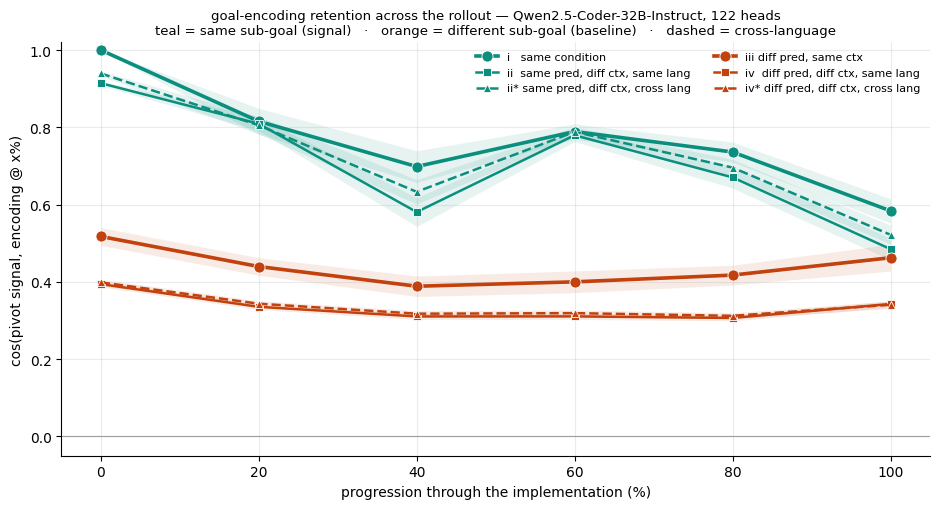

In [4]:
import json
import matplotlib.pyplot as plt
import numpy as np

# family = colour (teal = same sub-goal / signal; orange = different sub-goal / baseline);
# marker = context relation (o self·same-ctx, s diff-ctx same-lang, ^ cross-lang);
# dashed line = cross-language (secondary encoding). Palette validated (dataviz skill).
TEAL, ORANGE = '#0a8f7e', '#c2410c'
STYLE = {
    'i   same condition':                  (TEAL,   '-',  'o', 2.6, 8),
    'ii  same pred, diff ctx, same lang':  (TEAL,   '-',  's', 1.8, 6),
    'ii* same pred, diff ctx, cross lang': (TEAL,   '--', '^', 1.8, 6),
    'iii diff pred, same ctx':             (ORANGE, '-',  'o', 2.6, 8),
    'iv  diff pred, diff ctx, same lang':  (ORANGE, '-',  's', 1.8, 6),
    'iv* diff pred, diff ctx, cross lang': (ORANGE, '--', '^', 1.8, 6),
}

summ_path = os.path.join(TP.cache_dir(SLUG), 'summary.json')
if not os.path.exists(summ_path):
    print(f'no summary yet at {summ_path} — run scripts/evaluation/temporal_persistence_eval.py first')
else:
    S = json.load(open(summ_path))
    grid = S['prog_grid']; pooled = S['pooled']
    def cell(cur, p): return cur.get(str(p)) or cur.get(p)
    print('per-cell counts:', S['per_cell_counts'], '| total:', S['n_conditions_total'])
    t = Table(title=f"pooled retention — cos(pivot, enc @ x%)  ({S['n_conditions_total']} conds)")
    t.add_column('comparison'); t.add_column('n', justify='right')
    for p in grid: t.add_column(f'{int(p*100)}%', justify='right')
    for name, cur in pooled.items():
        col = 'sea_green3' if STYLE.get(name, ('',))[0] == TEAL else 'salmon1'
        row = [f'[{col}]{name}[/{col}]', str(cell(cur, grid[0])['n'])]
        row += [f"{cell(cur, p)['mean']:+.3f}" for p in grid]
        t.add_row(*row)
    rich_print(t)

    fig, ax = plt.subplots(figsize=(9.5, 5.2)); xs = [p*100 for p in grid]
    for name, cur in pooled.items():
        color, ls, mk, lw, ms = STYLE.get(name, ('grey', '-', 'o', 1.5, 5))
        mu = np.array([cell(cur, p)['mean'] for p in grid])
        er = np.array([cell(cur, p)['sem']  for p in grid])
        ax.plot(xs, mu, ls=ls, marker=mk, color=color, lw=lw, markersize=ms,
                markeredgecolor='white', markeredgewidth=0.6, label=name, zorder=3)
        ax.fill_between(xs, mu-er, mu+er, color=color, alpha=0.10, lw=0, zorder=1)
    ax.axhline(0, color='#999', lw=.8, zorder=0)
    ax.set_xlabel('progression through the implementation (%)')
    ax.set_ylabel('cos(pivot signal, encoding @ x%)')
    ax.set_title(f'goal-encoding retention across the rollout — {SLUG}, {HEAD_BUDGET} heads\n'
                 f'teal = same sub-goal (signal)   ·   orange = different sub-goal (baseline)   ·   '
                 f'dashed = cross-language', fontsize=9.5)
    ax.grid(alpha=.25, zorder=0); ax.set_ylim(top=1.02)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    ax.legend(fontsize=8, ncol=2, frameon=False, loc='upper right')
    plt.tight_layout(); plt.show()